# Section 8 — Trapezoidal and Simpson's Rules

[← Riemann Sums](07_riemann_sums.ipynb) ·
[Module 2](README.md)

The integration methods in this unit can be viewed as increasingly accurate
local polynomial approximations:

- Riemann sums: piecewise constants;
- trapezoidal rule: piecewise linear functions;
- Simpson's rule: piecewise quadratics.

### Learning goals

- use single and composite trapezoidal rules;
- use single and composite Simpson rules;
- apply the corresponding error bounds;
- compare the observed orders;
- choose a sufficient number of subintervals $n$ from a requested tolerance.


In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np


## Trapezoidal rule

On one interval $[a,b]$, with $h=b-a$,

$$
\int_a^b f(x)\,dx
\approx
\frac{h}{2}[f(a)+f(b)].
$$

For $n$ equal subintervals,

$$
T_n
=
\frac{h}{2}
\left[
f(x_0)
+2\sum_{j=1}^{n-1}f(x_j)
+f(x_n)
\right].
$$

The composite error bound is

$$
|E_T|
\le
\frac{b-a}{12}h^2
\max_{[a,b]}|f''(x)|.
$$


## Simpson's rule

For two subintervals,

$$
\int_a^b f(x)\,dx
\approx
\frac{h}{3}
[f(x_0)+4f(x_1)+f(x_2)],
$$

where $h=(b-a)/2$.

For composite Simpson with even $n$,

$$
S_n
=
\frac{h}{3}
\left[
f(x_0)
+4\sum_{\text{odd }j}f(x_j)
+2\sum_{\text{even }j}f(x_j)
+f(x_n)
\right].
$$

The composite error bound is

$$
|E_S|
\le
\frac{b-a}{180}h^4
\max_{[a,b]}|f^{(4)}(x)|.
$$


In [2]:
def composite_trapezoid(function, a, b, n):
    """Approximate an integral with composite trapezoids."""
    h = (b - a) / n
    x = np.linspace(a, b, n + 1)
    total = function(x[0]) + function(x[-1])
    total += 2.0 * np.sum(function(x[1:-1]))
    return 0.5 * h * total


def composite_simpson(function, a, b, n):
    """Approximate an integral with composite Simpson's rule."""
    if n % 2 != 0:
        raise ValueError("Simpson's rule requires even n.")

    h = (b - a) / n
    x = np.linspace(a, b, n + 1)

    total = function(x[0]) + function(x[-1])
    total += 4.0 * np.sum(function(x[1:-1:2]))
    total += 2.0 * np.sum(function(x[2:-1:2]))

    return (h / 3.0) * total


## Trapezoidal example from the course

Approximate

$$
\int_0^3\sin(2x)\,dx
$$

with one trapezoid and compute an error bound.

Since

$$
f''(x)=-4\sin(2x),
$$

we can take $M_2=4$.


In [3]:
def sine_function(x):
    return np.sin(2.0 * x)


a = 0.0
b = 3.0
h = b - a

trap_one = 0.5 * h * (
    sine_function(a)
    + sine_function(b)
)
exact = 0.5 * (1.0 - math.cos(6.0))
trap_error = abs(exact - trap_one)
trap_bound = h**3 * 4.0 / 12.0

print(f"trapezoid approximation = {trap_one:.10f}")
print(f"exact value             = {exact:.10f}")
print(f"actual error            = {trap_error:.10f}")
print(f"error bound             = {trap_bound:.10f}")


trapezoid approximation = -0.4191232473
exact value             = 0.0199148567
actual error            = 0.4390381040
error bound             = 9.0000000000


## Composite Simpson example

Approximate

$$
\int_1^2\frac1x\,dx
$$

using composite Simpson with $n=4$, then compare with $\ln2$.


In [4]:
def reciprocal(x):
    return 1.0 / x


simpson_value = composite_simpson(
    reciprocal,
    1.0,
    2.0,
    4,
)
exact_log = math.log(2.0)
simpson_error = abs(exact_log - simpson_value)

print(f"Simpson approximation = {simpson_value:.10f}")
print(f"exact ln(2)           = {exact_log:.10f}")
print(f"actual error          = {simpson_error:.3e}")


Simpson approximation = 0.6932539683
exact ln(2)           = 0.6931471806
actual error          = 1.068e-04


## Choosing $n$ from a tolerance

The review asks for an integer $n$ such that

$$
\int_{0.5}^{1}\frac1x\,dx
$$

is approximated with error less than $10^{-4}$.

For

$$
f(x)=\frac1x,
$$

we have

$$
f''(x)=\frac{2}{x^3},
\qquad
f^{(4)}(x)=\frac{24}{x^5}.
$$

On $[0.5,1]$,

$$
M_2=16,
\qquad
M_4=768.
$$

### Composite trapezoidal rule

With $h=(b-a)/n=0.5/n$,

$$
|E_T|
\le
\frac{0.5}{12}
\left(\frac{0.5}{n}\right)^2
16
=
\frac{1}{6n^2}.
$$

We require

$$
\frac{1}{6n^2}<10^{-4}.
$$

### Composite Simpson's rule

$$
|E_S|
\le
\frac{0.5}{180}
\left(\frac{0.5}{n}\right)^4
768
=
\frac{2}{15n^4}.
$$

Simpson also requires $n$ to be even.


In [5]:
tolerance = 1.0e-4

n_trap = math.floor(
    math.sqrt(1.0 / (6.0 * tolerance))
) + 1

n_simpson_threshold = (
    2.0 / (15.0 * tolerance)
) ** 0.25
n_simpson = math.floor(
    n_simpson_threshold
) + 1

if n_simpson % 2 != 0:
    n_simpson += 1

print(f"trapezoidal: n >= {n_trap}")
print(f"Simpson:     n >= {n_simpson}")


trapezoidal: n >= 41
Simpson:     n >= 8


## Compare observed orders

For a smooth function:

| Method | Typical global order |
|---|---:|
| Left/right Riemann | 1 |
| Midpoint | 2 |
| Trapezoidal | 2 |
| Simpson | 4 |


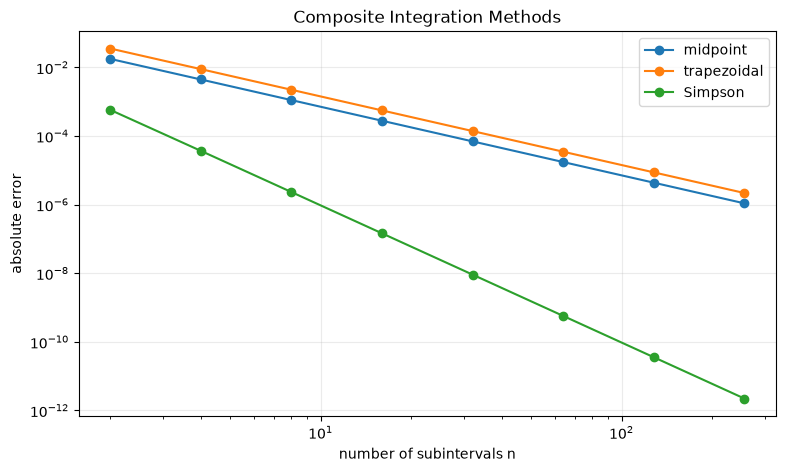

In [6]:
def midpoint_rule(function, a, b, n):
    h = (b - a) / n
    x = a + h * (
        np.arange(n)
        + 0.5
    )
    return h * np.sum(function(x))


def exp_function(x):
    return np.exp(x)


exact_exp = math.e - 1.0
n_values = 2 ** np.arange(1, 9)

mid_errors = []
trap_errors = []
simp_errors = []

for n in n_values:
    mid_errors.append(
        abs(
            exact_exp
            - midpoint_rule(
                exp_function,
                0.0,
                1.0,
                n,
            )
        )
    )
    trap_errors.append(
        abs(
            exact_exp
            - composite_trapezoid(
                exp_function,
                0.0,
                1.0,
                n,
            )
        )
    )
    simp_errors.append(
        abs(
            exact_exp
            - composite_simpson(
                exp_function,
                0.0,
                1.0,
                n,
            )
        )
    )

plt.figure(figsize=(9, 5))
plt.loglog(
    n_values,
    mid_errors,
    "o-",
    label="midpoint",
)
plt.loglog(
    n_values,
    trap_errors,
    "o-",
    label="trapezoidal",
)
plt.loglog(
    n_values,
    simp_errors,
    "o-",
    label="Simpson",
)
plt.xlabel("number of subintervals n")
plt.ylabel("absolute error")
plt.title("Composite Integration Methods")
plt.grid(alpha=0.25)
plt.legend()
plt.show()


### References

- Eric Sullivan, *Numerical Methods: An Inquiry-Based Approach with Python*.
- Leon Q. Brin, *Tea Time Numerical Analysis*.
- Richard L. Burden and J. Douglas Faires, *Numerical Analysis*.
- MAD 4401 Exam 2 review.

[← Module 2](README.md)
